# PaySim — Data profiling (Thành viên 2: Đạt)

Notebook W1 tái sử dụng EDA gốc, bổ sung manifest, schema, chất lượng dữ liệu và đề xuất xử lý cho ETL/ML.
Chạy từ trên xuống với `pandas`, `numpy`, `matplotlib`, `IPython` đã cài đặt
(`python -m pip install pandas numpy matplotlib ipython` nếu cần).
CSV khoảng 494 MB; cần vài GB RAM. Tất cả bảng và kiểm tra dùng **toàn bộ dữ liệu**;
chỉ scatter plot lấy mẫu 30.000 dòng, seed 42. Raw CSV không bị sửa.

Đường dẫn mặc định: `data/paysim dataset.csv`; có thể đặt biến môi trường `PAYSIM_DATA_PATH`.
Kết quả xuất vào `reports/data-profiling/` và `reports/data-quality-report.md`.
Nguồn tải, license, đơn vị tiền và ý nghĩa step còn cần xác nhận theo `docs/data-source.md`.
Không quy đổi amount sang VND; biểu đồ thời gian dùng step gốc, không tạo timestamp thực.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True})
RANDOM_STATE = 42


## 1. Đọc dữ liệu và xác định snapshot

Account IDs là định danh. `isFraud` là nhãn, `isFlaggedFraud` là cờ hệ thống để so sánh riêng.
`step` được mô tả trong EDA gốc là giờ mô phỏng, cần xác minh nguồn trước khi ánh xạ event time.
Số dư đích của merchant có thể không được ghi nhận; số 0 không tự động đồng nghĩa missing.

In [2]:
import os
import hashlib
import platform
from datetime import datetime, timezone

candidates = [Path('data/paysim dataset.csv'), Path('../data/paysim dataset.csv')]
if os.environ.get('PAYSIM_DATA_PATH'):
    candidates = [Path(os.environ['PAYSIM_DATA_PATH'])]
DATA_PATH = next((p.resolve() for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place paysim dataset.csv in data/ or set PAYSIM_DATA_PATH.')
ROOT = DATA_PATH.parent.parent
REPORT_DIR = (Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()) / 'reports'
OUTPUT_DIR = REPORT_DIR / 'data-profiling'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sha = hashlib.sha256()
with DATA_PATH.open('rb') as stream:
    for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
        sha.update(block)
fingerprint = sha.hexdigest()
# Infer numeric types first: narrowing integers before validation can hide invalid values.
df = pd.read_csv(DATA_PATH, dtype={'type': 'category', 'nameOrig': 'string', 'nameDest': 'string'})
expected_columns = ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg',
                    'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest',
                    'isFraud', 'isFlaggedFraud']
if df.columns.tolist() != expected_columns:
    raise ValueError(f'Unexpected schema: {df.columns.tolist()}')
numeric_columns = [c for c in expected_columns if c not in ['type', 'nameOrig', 'nameDest']]
if not all(pd.api.types.is_numeric_dtype(df[c]) for c in numeric_columns):
    raise ValueError('Non-numeric values in numeric fields: inspect raw CSV before profiling.')
manifest = {
    'file_name': DATA_PATH.name, 'sha256': fingerprint, 'file_size_bytes': DATA_PATH.stat().st_size,
    'row_count': len(df), 'columns': expected_columns, 'scope': 'full dataset',
    'run_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(), 'pandas': pd.__version__,
    'numpy': np.__version__, 'matplotlib': plt.matplotlib.__version__,
    'download_url': None, 'publisher_version': None, 'currency_unit': None,
    'provenance_status': 'Pending confirmation; see docs/data-source.md',
}
print(f'Loaded {len(df):,} rows, {df.shape[1]} columns; SHA-256: {fingerprint}')
print(f'DataFrame memory: {df.memory_usage(deep=True).sum() / 1024**2:,.1f} MB')
display(df.head())

Loaded 6,362,620 rows, 11 columns; SHA-256: 16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b
DataFrame memory: 1,213.4 MB


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0


## 2. Structure and Data Quality

Check column types, missing values, exact duplicate rows, and unexpected values before interpreting patterns. Duplicate rows are reported without automatically removing them.

In [3]:
df.info()
display(df.describe(include='number').T)
quality = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing_count': df.isna().sum(),
    'missing_percent': df.isna().mean() * 100,
})
display(quality)
print(f'Exact duplicate rows: {df.duplicated().sum():,}')
print(f'Negative transaction amounts: {(df["amount"] < 0).sum():,}')
for column in ['isFraud', 'isFlaggedFraud']:
    print(f'{column} values: {sorted(df[column].dropna().unique().tolist())}')


<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype   
---  ------          -----   
 0   step            int64   
 1   type            category
 2   amount          float64 
 3   nameOrig        string  
 4   oldbalanceOrg   float64 
 5   newbalanceOrig  float64 
 6   nameDest        string  
 7   oldbalanceDest  float64 
 8   newbalanceDest  float64 
 9   isFraud         int64   
 10  isFlaggedFraud  int64   
dtypes: category(1), float64(5), int64(3), string(2)
memory usage: 491.5 MB


,count,mean,std,min,25%,50%,75%,max
step,"6,362,620.0000",243.3972,142.3320,1.0000,156.0000,239.0000,335.0000,743.0000
amount,"6,362,620.0000","179,861.9035","603,858.2315",0.0000,"13,389.5700","74,871.9400","208,721.4775","92,445,516.6400"
oldbalanceOrg,"6,362,620.0000","833,883.1041","2,888,242.6730",0.0000,0.0000,"14,208.0000","107,315.1750","59,585,040.3700"
newbalanceOrig,"6,362,620.0000","855,113.6686","2,924,048.5030",0.0000,0.0000,0.0000,"144,258.4100","49,585,040.3700"
oldbalanceDest,"6,362,620.0000","1,100,701.6665","3,399,180.1130",0.0000,0.0000,"132,705.6650","943,036.7075","356,015,889.3500"
newbalanceDest,"6,362,620.0000","1,224,996.3982","3,674,128.9421",0.0000,0.0000,"214,661.4400","1,111,909.2500","356,179,278.9200"
isFraud,"6,362,620.0000",0.0013,0.0359,0.0000,0.0000,0.0000,0.0000,1.0000
isFlaggedFraud,"6,362,620.0000",0.0000,0.0016,0.0000,0.0000,0.0000,0.0000,1.0000


,dtype,missing_count,missing_percent
step,int64,0,0.0000
type,category,0,0.0000
amount,float64,0,0.0000
nameOrig,string,0,0.0000
oldbalanceOrg,float64,0,0.0000
newbalanceOrig,float64,0,0.0000
nameDest,string,0,0.0000
oldbalanceDest,float64,0,0.0000
newbalanceDest,float64,0,0.0000
isFraud,int64,0,0.0000


Exact duplicate rows: 0
Negative transaction amounts: 0
isFraud values: [0, 1]
isFlaggedFraud values: [0, 1]


## 3. Fraud Class Balance

Fraud is expected to be rare. Report counts and percentages together; accuracy alone can be misleading for an imbalanced dataset.

,count,percent
isFraud,,
0,6354407,99.8709
1,8213,0.1291


Overall fraud rate: 0.1291%


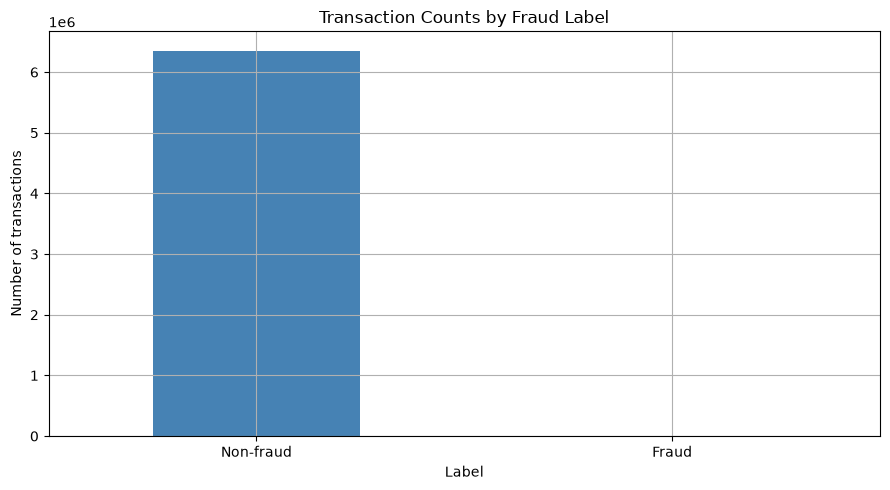

In [4]:
class_summary = df.groupby('isFraud').size().rename('count').to_frame()
class_summary['percent'] = class_summary['count'] / len(df) * 100
display(class_summary)
fraud_rate = df['isFraud'].mean() * 100
print(f'Overall fraud rate: {fraud_rate:.4f}%')

ax = class_summary['count'].rename(index={0: 'Non-fraud', 1: 'Fraud'}).plot.bar(color=['steelblue', 'tomato'])
ax.set(title='Transaction Counts by Fraud Label', xlabel='Label', ylabel='Number of transactions')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


## 4. Transaction Types

Compare transaction volume and fraud rate separately. A common transaction type does not necessarily have a high fraud rate.

,transactions,fraud_count,median_amount,total_amount,fraud_rate_percent
type,,,,,
CASH_OUT,2237500,4116,"147,072.1850","394,412,995,224.4900",0.1840
PAYMENT,2151495,0,"9,482.1900","28,093,371,138.3700",0.0000
CASH_IN,1399284,0,"143,427.7100","236,367,391,912.4600",0.0000
TRANSFER,532909,4097,"486,308.3900","485,291,987,263.1700",0.7688
DEBIT,41432,0,"3,048.9900","227,199,221.2800",0.0000


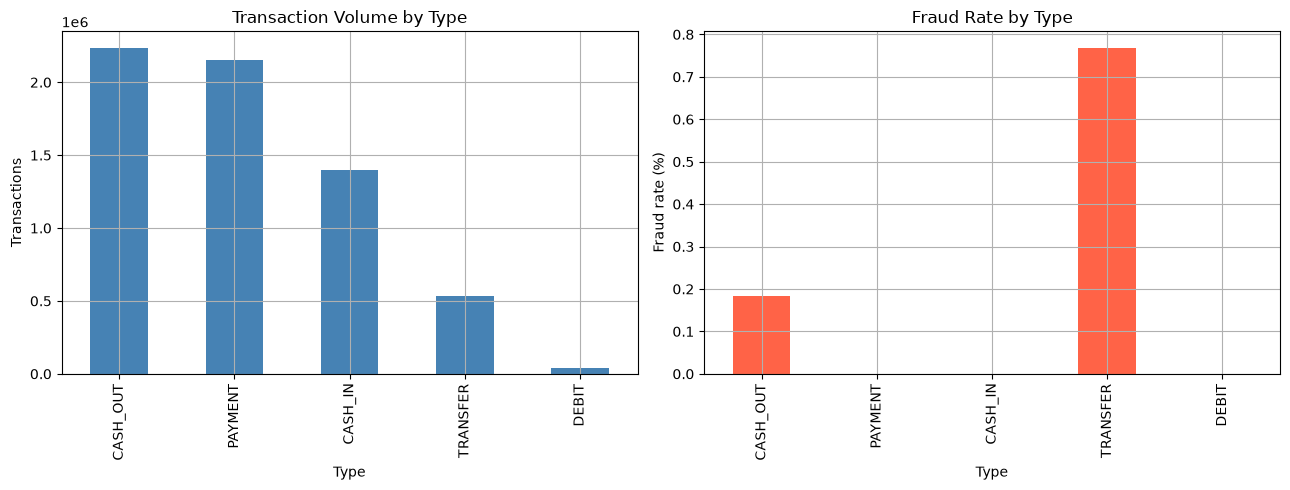

In [5]:
type_summary = df.groupby('type', observed=True).agg(
    transactions=('isFraud', 'size'),
    fraud_count=('isFraud', 'sum'),
    fraud_rate=('isFraud', 'mean'),
    median_amount=('amount', 'median'),
    total_amount=('amount', 'sum'),
).sort_values('transactions', ascending=False)
type_summary['fraud_rate_percent'] = type_summary.pop('fraud_rate') * 100
display(type_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
type_summary['transactions'].plot.bar(ax=axes[0], color='steelblue')
axes[0].set(title='Transaction Volume by Type', xlabel='Type', ylabel='Transactions')
type_summary['fraud_rate_percent'].plot.bar(ax=axes[1], color='tomato')
axes[1].set(title='Fraud Rate by Type', xlabel='Type', ylabel='Fraud rate (%)')
plt.tight_layout()
plt.show()


## 5. Transaction Amounts

Amounts can have a long right tail. Review quantiles and use a log transformation for the histogram. Negative amounts, if present, are excluded from this plot and were counted in the quality check.

isFraud,0,1
count,"6,354,407.0000","8,213.0000"
mean,"178,197.0417","1,467,967.2991"
std,"596,236.9813","2,404,252.9472"
min,0.0100,0.0000
50%,"74,684.7200","441,423.4400"
90%,"364,373.4440","4,521,723.5120"
99%,"1,586,064.1734","10,000,000.0000"
max,"92,445,516.6400","10,000,000.0000"


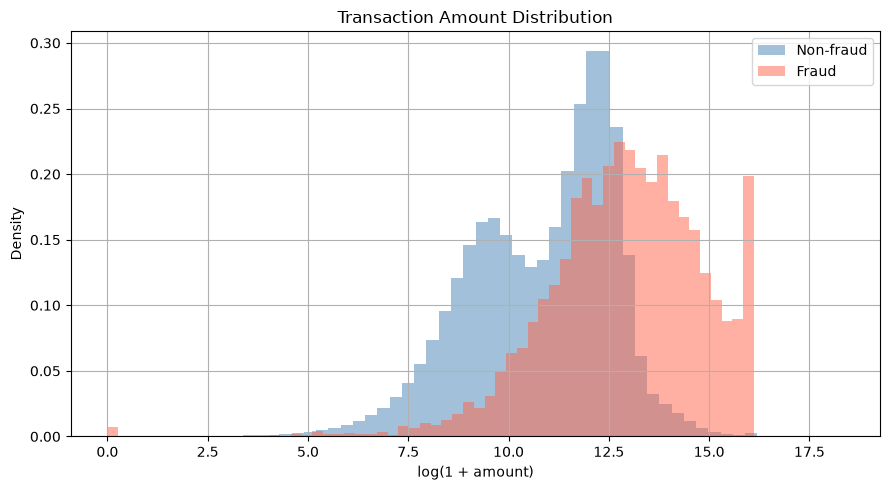

In [6]:
display(df.groupby('isFraud')['amount'].describe(percentiles=[0.5, 0.9, 0.99]).T)

fig, ax = plt.subplots()
for label, color in [(0, 'steelblue'), (1, 'tomato')]:
    amounts = df.loc[(df['isFraud'] == label) & (df['amount'] >= 0), 'amount']
    ax.hist(np.log1p(amounts), bins=60, density=True, alpha=0.5,
            label='Fraud' if label else 'Non-fraud', color=color)
ax.set(title='Transaction Amount Distribution', xlabel='log(1 + amount)', ylabel='Density')
ax.legend()
plt.tight_layout()
plt.show()


## 6. Activity Over Simulated Time

Aggregate by simulation step (hour). Changes in fraud rate should be read alongside transaction counts, especially in low-volume steps. These are simulated hours, not calendar timestamps.

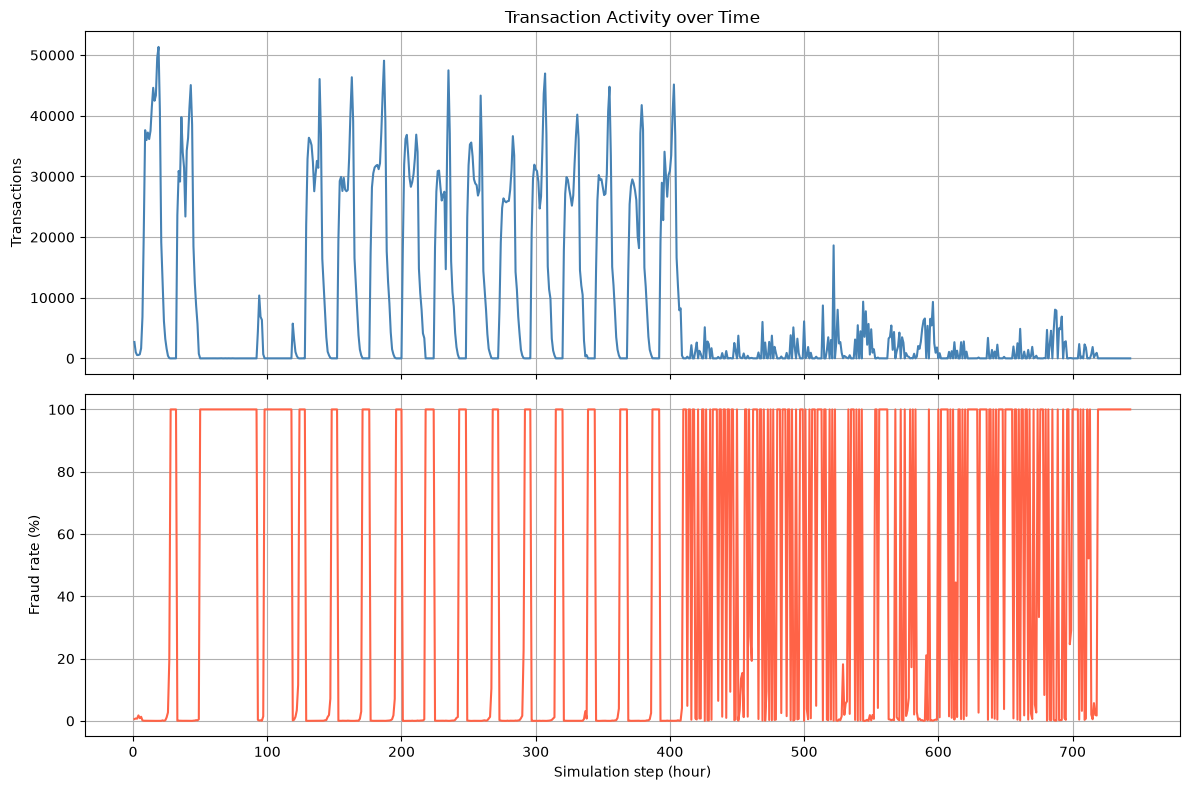

In [7]:
hourly = df.groupby('step').agg(
    transactions=('isFraud', 'size'), fraud_count=('isFraud', 'sum'),
    fraud_rate=('isFraud', 'mean'),
)
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(hourly.index, hourly['transactions'], color='steelblue')
axes[0].set(title='Transaction Activity over Time', ylabel='Transactions')
axes[1].plot(hourly.index, hourly['fraud_rate'] * 100, color='tomato')
axes[1].set(xlabel='Simulation step (hour)', ylabel='Fraud rate (%)')
plt.tight_layout()
plt.show()


## 7. Balances and Numeric Relationships

Correlation describes association, not causation. Exclude account identifiers and treat correlations with the rare fraud label carefully. Balance changes may contain information recorded after a transaction; assess feature availability before using them in a predictive model.

,correlation_with_fraud
isFraud,1.0000
amount,0.0767
isFlaggedFraud,0.0441
step,0.0316
oldbalanceOrg,0.0102
newbalanceDest,0.0005
oldbalanceDest,-0.0059
newbalanceOrig,-0.0081


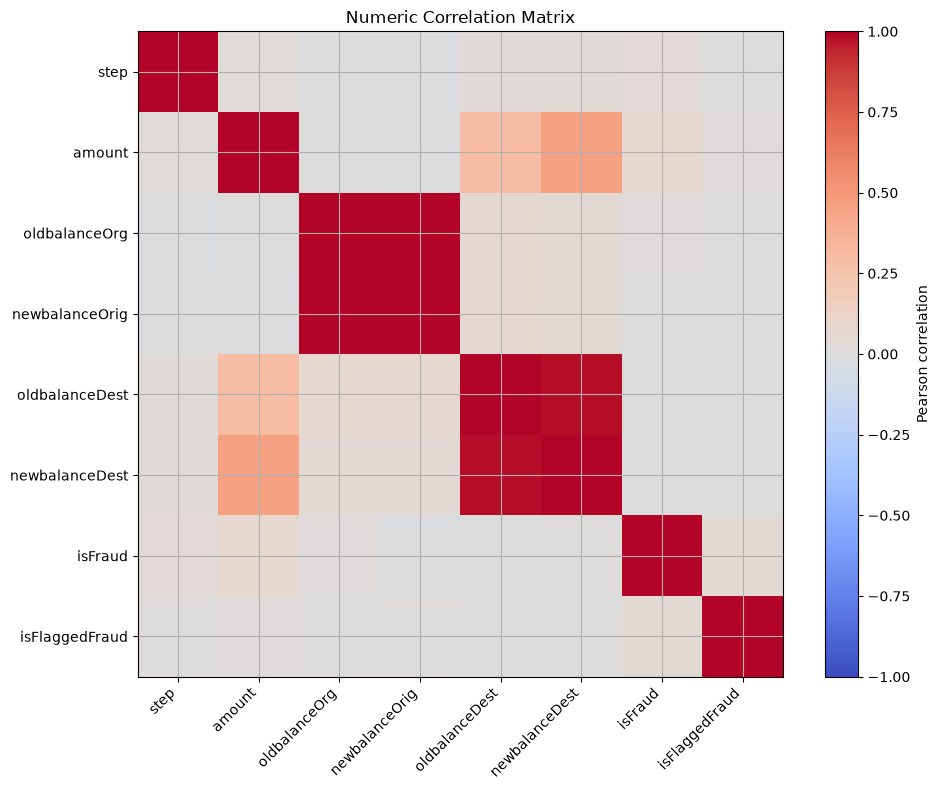

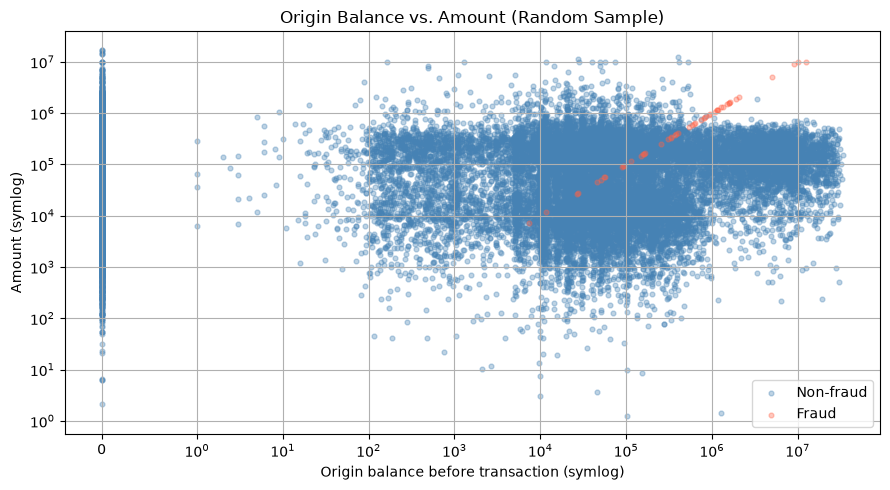

In [8]:
numeric_columns = ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
                   'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']
corr = df[numeric_columns].corr()
display(corr['isFraud'].sort_values(ascending=False).to_frame('correlation_with_fraud'))

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title('Numeric Correlation Matrix')
fig.colorbar(im, ax=ax, label='Pearson correlation')
plt.tight_layout()
plt.show()

# Sample only for visualization; all summary tables use the complete dataset.
sample = df.sample(n=min(30_000, len(df)), random_state=RANDOM_STATE)
fig, ax = plt.subplots()
for label, color in [(0, 'steelblue'), (1, 'tomato')]:
    subset = sample.loc[sample['isFraud'] == label]
    ax.scatter(subset['oldbalanceOrg'], subset['amount'], s=12, alpha=0.35,
               color=color, label='Fraud' if label else 'Non-fraud')
ax.set_xscale('symlog', linthresh=1)
ax.set_yscale('symlog', linthresh=1)
ax.set(title='Origin Balance vs. Amount (Random Sample)',
       xlabel='Origin balance before transaction (symlog)', ylabel='Amount (symlog)')
ax.legend()
plt.tight_layout()
plt.show()


## 8. Existing Fraud Flag

Compare the system flag with the fraud label. Precision measures how many flagged transactions are actually fraudulent; recall measures how many fraudulent transactions are flagged. These metrics evaluate the existing flag, not a trained model.

In [9]:
flag_table = pd.crosstab(df['isFraud'], df['isFlaggedFraud']).reindex(
    index=[0, 1], columns=[0, 1], fill_value=0)
display(flag_table.rename_axis(index='Actual fraud', columns='System flag'))
tn, fp = flag_table.loc[0, 0], flag_table.loc[0, 1]
fn, tp = flag_table.loc[1, 0], flag_table.loc[1, 1]
precision = tp / (tp + fp) if tp + fp else np.nan
recall = tp / (tp + fn) if tp + fn else np.nan
display(pd.Series({'precision': precision, 'recall': recall}, name='Existing flag metrics'))


System flag,0,1
Actual fraud,,
0,6354407,0
1,8197,16


precision   1.0000
recall      0.0019
Name: Existing flag metrics, dtype: float64

## 9. Profile từng cột và quy tắc chất lượng — toàn bộ dữ liệu

Kiểm tra null/blank, cardinality, miền giá trị, hữu hạn, label và category.
`duplicate_rows` đếm bản ghi lặp sau lần xuất hiện đầu; không tự xóa giao dịch.
Các rule có thể cùng xuất hiện trên một dòng: tổng count theo rule không phải số dòng quarantine.
IQR và sai lệch số dư là tín hiệu để điều tra, không phải nhãn fraud hay lý do tự loại dữ liệu.

In [10]:
column_profile = quality.copy()
column_profile['unique_count'] = df.nunique(dropna=True)
column_profile['blank_count'] = 0
for c in ['nameOrig', 'nameDest', 'type']:
    column_profile.loc[c, 'blank_count'] = int(df[c].astype('string').str.strip().eq('').sum())
column_profile['zero_count'] = pd.Series({c: int(df[c].eq(0).sum()) for c in numeric_columns})
column_profile['negative_count'] = pd.Series({c: int(df[c].lt(0).sum()) for c in numeric_columns})
column_profile['nonfinite_count'] = pd.Series({c: int((df[c].notna() & ~np.isfinite(df[c])).sum()) for c in numeric_columns})
display(column_profile)
numeric_summary = df[numeric_columns].describe(percentiles=[.01, .25, .5, .75, .95, .99, .999]).T
display(numeric_summary)
duplicate_rows = int(df.duplicated().sum())
invalid_any = np.zeros(len(df), dtype=bool)
rules = []
def add_rule(name, mask, policy):
    global invalid_any
    values = pd.Series(mask).fillna(False).to_numpy(dtype=bool)
    invalid_any |= values
    rules.append({'rule': name, 'count': int(values.sum()),
                  'percent': float(values.mean() * 100), 'proposed_policy': policy})

add_rule('required_null', df.isna().any(axis=1), 'Quarantine; preserve source row and reasons')
for c in ['nameOrig', 'nameDest', 'type']:
    add_rule(f'{c}_blank', df[c].astype('string').str.strip().eq(''), 'Quarantine; do not invent identifiers/categories')
for c in numeric_columns:
    add_rule(f'{c}_nonfinite', df[c].notna() & ~np.isfinite(df[c]), 'Quarantine; do not silently cast')
add_rule('step_nonpositive_or_fractional', df.step.le(0) | df.step.mod(1).ne(0), 'Quarantine; step must be a positive integer')
add_rule('amount_negative', df.amount.lt(0), 'Quarantine pending domain review')
for c in ['isFraud', 'isFlaggedFraud']:
    add_rule(f'{c}_outside_binary', df[c].notna() & ~df[c].isin([0, 1]), 'Quarantine; expected 0/1')
add_rule('unknown_type', df.type.notna() & ~df.type.isin(['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER']),
         'Quarantine/review contract; do not drop silently')
rule_summary = pd.DataFrame(rules)
print(f'Rows failing at least one proposed rule: {invalid_any.sum():,}')
print(f'Exact duplicate rows beyond first occurrence: {duplicate_rows:,}')
display(rule_summary)
q1, q3 = df.amount.quantile([.25, .75])
iqr = q3 - q1
amount_outliers = int((df.amount.lt(q1 - 1.5 * iqr) | df.amount.gt(q3 + 1.5 * iqr)).sum())
print(f'Zero amounts: {df.amount.eq(0).sum():,}; IQR outliers: {amount_outliers:,} (retain for review)')

,dtype,missing_count,missing_percent,unique_count,blank_count,zero_count,negative_count,nonfinite_count
step,int64,0,0.0000,743,0,0.0000,0.0000,0.0000
type,category,0,0.0000,5,0,NaN,NaN,NaN
amount,float64,0,0.0000,5316900,0,16.0000,0.0000,0.0000
nameOrig,string,0,0.0000,6353307,0,NaN,NaN,NaN
oldbalanceOrg,float64,0,0.0000,1845844,0,"2,102,449.0000",0.0000,0.0000
newbalanceOrig,float64,0,0.0000,2682586,0,"3,609,566.0000",0.0000,0.0000
nameDest,string,0,0.0000,2722362,0,NaN,NaN,NaN
oldbalanceDest,float64,0,0.0000,3614697,0,"2,704,388.0000",0.0000,0.0000
newbalanceDest,float64,0,0.0000,3555499,0,"2,439,433.0000",0.0000,0.0000
isFraud,int64,0,0.0000,2,0,"6,354,407.0000",0.0000,0.0000


,count,mean,std,min,1%,25%,50%,75%,95%,99%,99.9%,max
step,"6,362,620.0000",243.3972,142.3320,1.0000,9.0000,156.0000,239.0000,335.0000,490.0000,681.0000,710.0000,743.0000
amount,"6,362,620.0000","179,861.9035","603,858.2315",0.0000,449.4676,"13,389.5700","74,871.9400","208,721.4775","518,634.1965","1,615,979.4716","8,956,797.6770","92,445,516.6400"
oldbalanceOrg,"6,362,620.0000","833,883.1041","2,888,242.6730",0.0000,0.0000,0.0000,"14,208.0000","107,315.1750","5,823,702.2785","16,027,256.1337","26,825,930.2048","59,585,040.3700"
newbalanceOrig,"6,362,620.0000","855,113.6686","2,924,048.5030",0.0000,0.0000,0.0000,0.0000,"144,258.4100","5,980,262.3365","16,176,160.5580","26,971,658.9303","49,585,040.3700"
oldbalanceDest,"6,362,620.0000","1,100,701.6665","3,399,180.1130",0.0000,0.0000,0.0000,"132,705.6650","943,036.7075","5,147,229.7135","12,371,819.1548","34,392,786.7880","356,015,889.3500"
newbalanceDest,"6,362,620.0000","1,224,996.3982","3,674,128.9421",0.0000,0.0000,0.0000,"214,661.4400","1,111,909.2500","5,515,715.9035","13,137,866.9410","39,531,571.9674","356,179,278.9200"
isFraud,"6,362,620.0000",0.0013,0.0359,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000
isFlaggedFraud,"6,362,620.0000",0.0000,0.0016,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000


Rows failing at least one proposed rule: 0
Exact duplicate rows beyond first occurrence: 0


,rule,count,percent,proposed_policy
0,required_null,0,0.0000,Quarantine; preserve source row and reasons
1,nameOrig_blank,0,0.0000,Quarantine; do not invent identifiers/categories
2,nameDest_blank,0,0.0000,Quarantine; do not invent identifiers/categories
3,type_blank,0,0.0000,Quarantine; do not invent identifiers/categories
4,step_nonfinite,0,0.0000,Quarantine; do not silently cast
5,amount_nonfinite,0,0.0000,Quarantine; do not silently cast
6,oldbalanceOrg_nonfinite,0,0.0000,Quarantine; do not silently cast
7,newbalanceOrig_nonfinite,0,0.0000,Quarantine; do not silently cast
8,oldbalanceDest_nonfinite,0,0.0000,Quarantine; do not silently cast
9,newbalanceDest_nonfinite,0,0.0000,Quarantine; do not silently cast


Zero amounts: 16; IQR outliers: 338,078 (retain for review)


## 10. Số dư và định danh — toàn bộ dữ liệu

Sai lệch tính với dung sai tuyệt đối 0,01 theo đơn vị amount gốc.
Origin: `new - old - sign × amount`, sign +1 cho CASH_IN và −1 cho các type còn lại.
Destination: chỉ CASH_IN (−1), CASH_OUT/TRANSFER (+1) với tài khoản C và có ít nhất
một số dư đích khác 0. Loại merchant và trường hợp cả hai số dư bằng 0 khỏi phép đối chiếu đích;
báo riêng số lượng. Công thức là giả thuyết kiểm tra, chưa phải validator ETL được nhóm chốt.

In [11]:
balance_rows = []
for transaction_type in type_summary.index:
    part = df.loc[df.type.eq(transaction_type)]
    origin_sign = 1 if transaction_type == 'CASH_IN' else -1
    origin_error = part.newbalanceOrig - part.oldbalanceOrg - origin_sign * part.amount
    dest_sign = {'CASH_IN': -1, 'CASH_OUT': 1, 'TRANSFER': 1}.get(str(transaction_type))
    eligible = part.nameDest.str.startswith('C').fillna(False) & (part.oldbalanceDest.ne(0) | part.newbalanceDest.ne(0))
    if dest_sign is None:
        eligible = pd.Series(False, index=part.index)
    dest_error = part.newbalanceDest - part.oldbalanceDest - (dest_sign or 0) * part.amount
    balance_rows.append({'type': str(transaction_type), 'rows': len(part),
        'origin_mismatch': int(origin_error.abs().gt(.01).sum()),
        'destination_eligible': int(eligible.sum()),
        'destination_mismatch': int((eligible & dest_error.abs().gt(.01)).sum()),
        'destination_excluded': int((~eligible).sum()),
        'both_destination_balances_zero': int((part.oldbalanceDest.eq(0) & part.newbalanceDest.eq(0)).sum())})
balance_summary = pd.DataFrame(balance_rows).set_index('type')
display(balance_summary)
account_summary = pd.DataFrame({
    'distinct_accounts': [df.nameOrig.nunique(), df.nameDest.nunique()],
    'customer_prefix_rows': [df.nameOrig.str.startswith('C').sum(), df.nameDest.str.startswith('C').sum()],
    'merchant_prefix_rows': [df.nameOrig.str.startswith('M').sum(), df.nameDest.str.startswith('M').sum()],
}, index=['origin', 'destination'])
display(account_summary)
step_summary = hourly.copy()
step_summary['fraud_rate_percent'] = step_summary.pop('fraud_rate') * 100
print(f'Step range: {df.step.min()}–{df.step.max()}; observed steps: {df.step.nunique():,}')
print(f'Source ordered by step: {df.step.is_monotonic_increasing}')

,rows,origin_mismatch,destination_eligible,destination_mismatch,destination_excluded,both_destination_balances_zero
type,,,,,,
CASH_OUT,2237500,1990338,2235892,441922,1608,1608
PAYMENT,2151495,1155712,0,0,2151495,2151495
CASH_IN,1399284,110676,1239279,345629,160005,160005
TRANSFER,532909,508748,528735,115376,4174,4174
DEBIT,41432,12343,0,0,41432,0


,distinct_accounts,customer_prefix_rows,merchant_prefix_rows
origin,6353307,6362620,0
destination,2722362,4211125,2151495


Step range: 1–743; observed steps: 743
Source ordered by step: True


## 11. Bàn giao ETL/ML và giới hạn

- Feature MVP đề xuất: amount (hoặc log1p) và type. Old balances/step chỉ dùng sau khi xác nhận nghĩa và scoring input.
- `isFraud` chỉ là label; `isFlaggedFraud` chỉ là baseline rule riêng. New balances và residual số dư có thể chứa thông tin sau giao dịch, cần review availability.
- Account IDs để truy vết/history, không one-hot hàng triệu ID. CSV không có transaction ID: đề xuất SHA-256 snapshot + tên file + vị trí dòng nguồn, lưu từ ingestion trước sort/filter; không dùng thứ tự partition Spark.
- Zero amount/balance, IQR outliers và duplicates giữ nguyên để review. Null/miền sai/nonfinite đề xuất quarantine có audit. Notebook chỉ báo cáo, chưa thực thi ETL.
- Khi chia train/validation/test theo thời gian, giữ cùng step trong cùng split và kiểm tra fraud count từng tập; chưa chốt cutoff hay huấn luyện model ở đây.
- Cần Lead/Đạt xác nhận nguồn, license, đơn vị tiền và step; Thái review label/availability; Công Anh review scoring fields; Đức Anh review validation policy trước khi chốt W1. Deadline tương đối: cuối W1, chưa có ngày lịch được nhóm xác nhận.

PaySim là dữ liệu mô phỏng theo EDA gốc. Kết quả profiling không chứng minh chất lượng trên giao dịch ngân hàng thực.

In [12]:
import json

tables = {'column_profile': column_profile, 'numeric_summary': numeric_summary,
          'quality_rules': rule_summary, 'class_distribution': class_summary,
          'transaction_types': type_summary, 'step_distribution': step_summary,
          'balance_checks': balance_summary, 'account_summary': account_summary,
          'flag_confusion': flag_table}
for name, table in tables.items():
    table.to_csv(OUTPUT_DIR / f'{name}.csv', index=True)
manifest.update({'duplicate_rows': duplicate_rows, 'invalid_rows_proposed_rules': int(invalid_any.sum()),
                 'fraud_count': int(df.isFraud.eq(1).sum()), 'step_min': int(df.step.min()),
                 'step_max': int(df.step.max()), 'amount_iqr_outliers': amount_outliers})
(OUTPUT_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
lines = [
    '# PaySim data quality report', '',
    'Generated by `notebooks/01_data_profiling.ipynb`; all checks use the full local CSV.', '',
    f'- Run UTC: {manifest["run_utc"]}', f'- SHA-256: `{fingerprint}`',
    f'- File size: {manifest["file_size_bytes"]:,} bytes',
    f'- Rows: {len(df):,}; columns: {df.shape[1]}',
    f'- Fraud: {manifest["fraud_count"]:,} ({fraud_rate:.4f}%)',
    f'- Step range: {manifest["step_min"]}–{manifest["step_max"]}',
    f'- Missing cells: {int(df.isna().sum().sum()):,}',
    f'- Duplicate rows beyond first occurrence: {duplicate_rows:,}; retain pending review',
    f'- Rows failing one or more proposed rules: {int(invalid_any.sum()):,}',
    f'- Zero amounts: {int(df.amount.eq(0).sum()):,}; retain pending review',
    f'- Amount IQR outliers: {amount_outliers:,}; retain, not automatically fraud',
    f'- Existing flag precision: {precision:.6f}; recall: {recall:.6f} (rule baseline only)',
    '', '## Rules and proposed policy', '',
    '| Rule | Rows | Proposed policy |', '|---|---:|---|',
]
lines += [f'| {r.rule} | {r.count:,} | {r.proposed_policy} |' for r in rule_summary.itertuples(index=False)]
lines += ['', 'Rules overlap; counts must not be summed to calculate quarantine rows.',
          '', '## Balance checks (absolute tolerance 0.01)', '',
          '| Type | Origin mismatches | Destination eligible | Destination mismatches | Destination excluded |',
          '|---|---:|---:|---:|---:|']
lines += [f'| {t} | {r.origin_mismatch:,} | {r.destination_eligible:,} | {r.destination_mismatch:,} | {r.destination_excluded:,} |'
          for t, r in balance_summary.iterrows()]
lines += ['', 'Balance formulas and destination coverage are described in notebook section 10. '
          'These counts are investigation signals, not automatic fraud labels or rejection rules.',
          '', '## Handoff and open decisions', '',
          '- MVP candidates: amount/log1p(amount) and type; review step/old balances before inclusion.',
          '- Exclude label, existing flag, new balances and balance residuals from default scoring features.',
          '- Preserve account IDs for traceability; propose snapshot/file/source-row identity at ingestion.',
          '- Source URL/version/license, currency, step semantics: Lead/Đạt, by end of W1.',
          '- Label/feature availability: Thái; scoring fields: Công Anh; validation policy: Đức Anh, by end of W1.',
          '- No calendar deadline, scoring contract, timestamp anchor or ETL policy has been approved here.',
          '- Raw data is retained unchanged; no imputation, clipping, deduplication or model fitting.',
          '- CSV parser/schema failures stop execution rather than silently skipping malformed records.',
          '', 'Detailed CSV tables and runtime/snapshot manifest: `data-profiling/`. '
          'See `../docs/data-source.md` for unresolved source provenance.']
(REPORT_DIR / 'data-quality-report.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')
print(f'Exported {len(tables)} tables, manifest and quality report to {REPORT_DIR}')

Exported 9 tables, manifest and quality report to c:\Users\lenovo\project\bigdata\reports
